# Industry Project: Retail Demand Forecasting for Store Replenishment (Production-Style)

> **Who is this notebook for?** Someone who has seen the forecasting basics (lags, ARIMA, LightGBM) but has never built a
> forecasting system that a real business runs every week. You do **not** need the math from the other notebooks:
> every step is explained in plain English and almost every line of code has a comment.

---

### How this notebook is different from the others in `04_Forecasting/`

| Other notebooks in this folder (e.g. `03_ml_for_forecasting.ipynb`) | This notebook |
|---|---|
| One (or a few) clean series | **400 series** (10 stores x 40 products), like a small version of the Walmart **M5** competition |
| Explain what lag features and multi-step strategies **are** | Build them **point-in-time correct** and **prove** there is no leakage with a test |
| A single train/test split | **Rolling-origin backtesting** (4 forecast "dates in the past") |
| RMSE / MAPE on one series | **WAPE, bias, MASE** per product group and per demand type (fast, intermittent, ...) |
| Stops at the forecast | Turns forecasts into **order quantities** and measures the **$ cost** of over- and under-stock |
| - | Saving the model, a `forecast_next_14_days()` function with input checks, **monitoring** forecast error after go-live |

---

### The business problem

You work for a regional retail chain with **10 stores** and **40 products** in three groups (FOODS, HOUSEHOLD, HOBBIES).
Every second Tuesday the replenishment system orders stock for each store and product, which must last for the next **14 days**.

- Ordering **too little** means empty shelves: the chain loses the margin on every unit it could have sold (and annoys customers).
- Ordering **too much** costs money too: storage, capital tied up, and for FOODS, products that **spoil** and are thrown away.

Today, planners order "what we sold in the last two weeks". **Your job:** build a forecasting system that

1. predicts daily sales per store and product for the next 14 days,
2. is **more accurate** than the planners' simple rules (measured honestly on past periods),
3. gives **order quantities** that reduce the total cost of over- and under-stocking,
4. can be **run every two weeks** by a scheduled job, and **raises an alarm** when the forecast goes wrong.

---

### The forecasting workflow we will follow

```
 1. Sales + prices + calendar  ->  2. Clean into a complete daily panel  ->  3. Validate
                                                                               |
 10. Monitor errors  <-  9. Forecast function  <-  8. Save  <-  7. Orders + $  <-  4. Baselines
                                                                  ^                 |
                                    6. Quantiles (uncertainty) ---+   5. LightGBM global model
                                                                       (rolling-origin backtest)
```

### Table of Contents
1. Setup: imports and one central config
2. Get the data (sales, prices/promotions and a calendar, like M5)
3. First look at the data
4. Clean the data: build a complete daily panel
5. Validate the data
6. Know your series: fast, erratic, intermittent and lumpy demand
7. Honest evaluation: rolling-origin backtesting, baselines and metrics
8. Point-in-time correct features (and a leakage test)
9. A global LightGBM model, backtested
10. Error analysis: per product group, per demand type, per horizon day
11. Recursive vs direct multi-step forecasting
12. Quantile forecasts: how uncertain are we?
13. From forecasts to orders: the cost of over- and under-stock
14. Train the final model and save it with metadata
15. A forecast function with input validation
16. Monitoring: detect when the forecast goes wrong after go-live
17. Automated tests
18. Summary, exercises and resources

---
## 1. Setup: imports and one central config

All important numbers live in one `Config`: the forecast horizon, the backtest design, the model settings and the business costs.
If the business says "we now order every 7 days", you change **one** value.

In [1]:
# ---- Standard library ----
import json                      # save model metadata as readable text
import logging                   # timestamped status messages instead of print()
import tempfile                  # temporary folder for the saved model (keeps the repo clean)
import time                      # measure how long training takes
import warnings                  # hide noisy library warnings in this tutorial
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party libraries ----
import joblib                    # save / load Python objects (our model bundle)
import lightgbm as lgb           # gradient-boosted trees, the most used model in the M5 competition
import matplotlib.pyplot as plt  # plotting
import numpy as np               # numerical arrays
import pandas as pd              # tables

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)      # keep matplotlib's own messages quiet
log = logging.getLogger("demand_forecast")


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    horizon: int = 14                          # we forecast 14 days ahead (one replenishment cycle)
    today: str = "2025-09-30"                  # the "current date": everything after it is the unknown future
    n_backtest_folds: int = 4                  # how many past forecast dates we simulate
    train_window_days: int = 365               # train on the last year before each forecast date
    # Lags of at least `horizon` days -> one model can forecast all 14 days without using its own predictions
    lags: tuple = (14, 21, 28, 35, 42, 49)
    rolling_windows: tuple = (7, 28, 56)
    lgbm_params: dict = field(default_factory=lambda: dict(
        objective="tweedie",              # good for counts with many zeros (popular in M5 solutions)
        tweedie_variance_power=1.2,
        learning_rate=0.08, n_estimators=200, num_leaves=31, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, max_bin=127,
        verbose=-1, n_jobs=2, random_state=42))   # 2 threads: fastest on our busy shared CPU
    # Business costs, as a share of the selling price per unit
    underage_rate: dict = field(default_factory=lambda: {"FOODS": 0.30, "HOUSEHOLD": 0.35, "HOBBIES": 0.40})  # lost margin
    overage_rate: dict = field(default_factory=lambda: {"FOODS": 0.25, "HOUSEHOLD": 0.04, "HOBBIES": 0.05})   # waste/holding


CFG = Config()
TODAY = pd.Timestamp(CFG.today)
KEYS = ["store_id", "item_id"]                 # one time series = one store x one product
np.random.seed(CFG.random_state)
log.info("pandas %s | lightgbm %s", pd.__version__, lgb.__version__)

2026-10-21 17:29:12,085 | INFO | pandas 2.3.3 | lightgbm 4.6.0


---
## 2. Get the data (sales, prices/promotions and a calendar, like M5)

The famous **M5 forecasting competition** (Walmart data, Kaggle 2020) gives three tables, and real retailers have the same three:

| Table | Comes from | Example SQL in real life |
|---|---|---|
| `sales` | point-of-sale (POS) system, aggregated per store, product and day | `SELECT store_id, item_id, sale_date, SUM(qty) FROM pos_lines GROUP BY 1,2,3` |
| `prices` | merchandising / pricing system: the planned price and promotions, **known in advance** | `SELECT * FROM price_plan WHERE valid_date <= :today + 14` |
| `calendar` | a holiday / event calendar maintained by the business | `SELECT * FROM retail_calendar` |

So the notebook runs offline, we **simulate** these tables with a fixed seed. The simulator includes what makes retail data hard:
trend, weekly and yearly seasonality, holidays (Black Friday, Christmas closures, ...), promotions with price drops, many
slow-moving products with lots of zero days, products launched recently, random noise, and **missing days** where the POS export
failed for a whole store. You can skip the details of the generator code.

In [2]:
def make_event_calendar(start, end) -> pd.DataFrame:
    """The retail calendar: one row per special day with an event name (like M5's calendar.csv)."""
    rows = []
    for year in range(pd.Timestamp(start).year, pd.Timestamp(end).year + 1):
        november = pd.date_range(f"{year}-11-01", f"{year}-11-30")
        thanksgiving = november[november.dayofweek == 3][3]                 # 4th Thursday of November
        february = pd.date_range(f"{year}-02-01", f"{year}-02-14")
        super_bowl = february[february.dayofweek == 6][1]                    # 2nd Sunday of February
        september = pd.date_range(f"{year}-09-01", f"{year}-09-07")
        labor_day = september[september.dayofweek == 0][0]                  # 1st Monday of September
        rows += [(pd.Timestamp(f"{year}-01-01"), "new_year"), (super_bowl, "super_bowl"),
                 (pd.Timestamp(f"{year}-07-04"), "independence_day"), (labor_day, "labor_day"),
                 (thanksgiving, "thanksgiving"), (thanksgiving + pd.Timedelta(days=1), "black_friday"),
                 (pd.Timestamp(f"{year}-12-24"), "christmas_eve"), (pd.Timestamp(f"{year}-12-25"), "christmas"),
                 (pd.Timestamp(f"{year}-12-31"), "new_years_eve")]
        rows += [(d, "xmas_run_up") for d in pd.date_range(f"{year}-12-10", f"{year}-12-23")]
    cal = pd.DataFrame(rows, columns=["date", "event"])
    return cal[(cal["date"] >= pd.Timestamp(start)) & (cal["date"] <= pd.Timestamp(end))].reset_index(drop=True)


# How much each event multiplies demand, per product group (hidden "truth" of the simulator)
EVENT_LIFT = {
    "new_year": {"FOODS": 0.8, "HOUSEHOLD": 0.6, "HOBBIES": 0.7},
    "super_bowl": {"FOODS": 1.4, "HOUSEHOLD": 1.0, "HOBBIES": 0.9},
    "independence_day": {"FOODS": 1.5, "HOUSEHOLD": 1.0, "HOBBIES": 1.1},
    "labor_day": {"FOODS": 1.3, "HOUSEHOLD": 1.1, "HOBBIES": 1.0},
    "thanksgiving": {"FOODS": 0.7, "HOUSEHOLD": 0.4, "HOBBIES": 0.4},
    "black_friday": {"FOODS": 1.1, "HOUSEHOLD": 1.8, "HOBBIES": 2.0},
    "christmas_eve": {"FOODS": 1.4, "HOUSEHOLD": 0.9, "HOBBIES": 1.3},
    "christmas": {"FOODS": 0.0, "HOUSEHOLD": 0.0, "HOBBIES": 0.0},       # stores are closed
    "new_years_eve": {"FOODS": 1.3, "HOUSEHOLD": 0.9, "HOBBIES": 0.9},
    "xmas_run_up": {"FOODS": 1.1, "HOUSEHOLD": 1.15, "HOBBIES": 1.5},
}


def simulate_retail_data(start="2023-01-01", end="2025-12-05", n_stores=10, seed=7,
                         drift_store="S07", drift_start="2025-10-22", drift_factor=0.65):
    """Return (sales, prices) tables that behave like a real retail chain. Demand is negative-binomial-like."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, end, freq="D")
    n_days, years = len(dates), np.arange(len(dates)) / 365.0
    categories = ["FOODS"] * 18 + ["HOUSEHOLD"] * 12 + ["HOBBIES"] * 10
    item_ids = [f"{c[:3]}_{i:03d}" for i, c in enumerate(categories)]
    item_base = rng.lognormal(0.6, 1.0, len(categories)).clip(0.15, 25)    # fast AND very slow products
    base_price = np.round(rng.uniform(1.5, 25, len(categories)), 2)
    elasticity = rng.uniform(-2.2, -0.8, len(categories))                     # cheaper -> sells more
    promo_lift = rng.uniform(1.2, 1.8, len(categories))                       # extra lift from promo display
    store_size = rng.lognormal(0, 0.35, n_stores)
    store_growth = rng.normal(0.04, 0.05, n_stores)                           # some stores grow, some shrink
    weekly = {"FOODS": [0.9, 0.85, 0.85, 0.9, 1.05, 1.3, 1.15], "HOUSEHOLD": [0.95, 0.9, 0.9, 0.95, 1.0, 1.25, 1.05],
              "HOBBIES": [0.8, 0.8, 0.85, 0.9, 1.05, 1.45, 1.25]}           # Mon..Sun
    yearly_amp, yearly_peak = {"FOODS": 0.08, "HOUSEHOLD": 0.12, "HOBBIES": 0.2}, {"FOODS": 200, "HOUSEHOLD": 110, "HOBBIES": 340}
    events = make_event_calendar(start, end).groupby("date")["event"].first()
    event_of_day = pd.Series(dates).map(events).values
    launches = {len(categories) - 1: "2024-06-01", len(categories) - 5: "2024-09-15", 3: "2025-03-01"}  # new products
    sales_frames, price_frames = [], []
    for i, cat in enumerate(categories):
        regular = np.full(n_days, base_price[i])
        for change_day in rng.choice(n_days, 2, replace=False):                 # two permanent price changes
            regular[change_day:] *= rng.uniform(0.95, 1.12)
        promo = np.zeros(n_days, dtype=int)
        for s in rng.choice(n_days - 7, rng.integers(6, 14), replace=False):   # 7-day promotions, chain-wide
            promo[s:s + 7] = 1
        price = np.round(np.where(promo == 1, regular * rng.uniform(0.7, 0.85), regular), 2)
        seasonal = np.array(weekly[cat])[dates.dayofweek] * (1 + yearly_amp[cat] * np.cos(2 * np.pi * (dates.dayofyear - yearly_peak[cat]) / 365))
        event_effect = np.array([EVENT_LIFT[e][cat] if isinstance(e, str) else 1.0 for e in event_of_day])
        demand_driver = (item_base[i] * (1 + rng.normal(0, 0.06) * years) * seasonal * event_effect
                         * (price / regular) ** elasticity[i] * np.where(promo == 1, promo_lift[i], 1.0))
        for s in range(n_stores):
            store = f"S{s + 1:02d}"
            lam = demand_driver * store_size[s] * (1 + store_growth[s] * years)
            if store == drift_store:                                            # a competitor opens next door
                lam = lam * np.where(dates >= pd.Timestamp(drift_start), drift_factor, 1.0)
            qty = rng.poisson(lam * rng.gamma(4.0, 0.25, n_days))               # gamma noise = weather, local events
            frame = pd.DataFrame({"date": dates, "store_id": store, "item_id": item_ids[i], "category": cat,
                                  "sales": qty, "sell_price": price, "on_promo": promo})
            if i in launches:
                frame = frame[frame["date"] >= launches[i]]                     # no history before launch
            sales_frames.append(frame[["date", "store_id", "item_id", "category", "sales"]])
            price_frames.append(frame[["date", "store_id", "item_id", "sell_price", "on_promo"]])
    sales = pd.concat(sales_frames, ignore_index=True)
    prices = pd.concat(price_frames, ignore_index=True)
    # POS export outages: ~1.2% of store-days are simply MISSING from the sales table
    store_days = sales[["store_id", "date"]].drop_duplicates()
    outages = store_days.sample(frac=0.012, random_state=seed).assign(_outage=1)
    sales = sales.merge(outages, on=["store_id", "date"], how="left")
    sales = sales[sales["_outage"].isna()].drop(columns="_outage").reset_index(drop=True)
    return sales, prices


all_sales, all_prices = simulate_retail_data()
calendar = make_event_calendar("2023-01-01", "2026-12-31")

# Freeze "today": the model may only see sales up to TODAY. Prices/promos are planned, so the next 14 days are known.
sales = all_sales[all_sales["date"] <= TODAY].copy()
future_actuals = all_sales[all_sales["date"] > TODAY].copy()     # hidden; used ONLY in the monitoring section
prices = all_prices.copy()                                        # the price plan (in reality: up to today + horizon)
print(f"sales: {sales.shape[0]:,} rows | prices: {prices.shape[0]:,} rows | calendar: {len(calendar)} special days")
sales.head()

sales: 377,857 rows | prices: 408,700 rows | calendar: 92 special days


,date,store_id,item_id,category,sales
0,2023-01-01,S01,FOO_000,FOODS,3
1,2023-01-02,S01,FOO_000,FOODS,3
2,2023-01-03,S01,FOO_000,FOODS,5
3,2023-01-04,S01,FOO_000,FOODS,2
4,2023-01-05,S01,FOO_000,FOODS,0


---
## 3. First look at the data

Questions a forecaster asks first: how many series, how long is the history, how much of the data is **zero**, and what do the
big patterns (trend, seasonality, holidays) look like at the top level?

400 series | 2023-01-01 -> 2025-09-30
Share of zero-sales days: 36.7%


           mean_per_day  zero_share
category                           
FOODS              2.09        0.30
HOBBIES            2.06        0.37
HOUSEHOLD          1.23        0.46


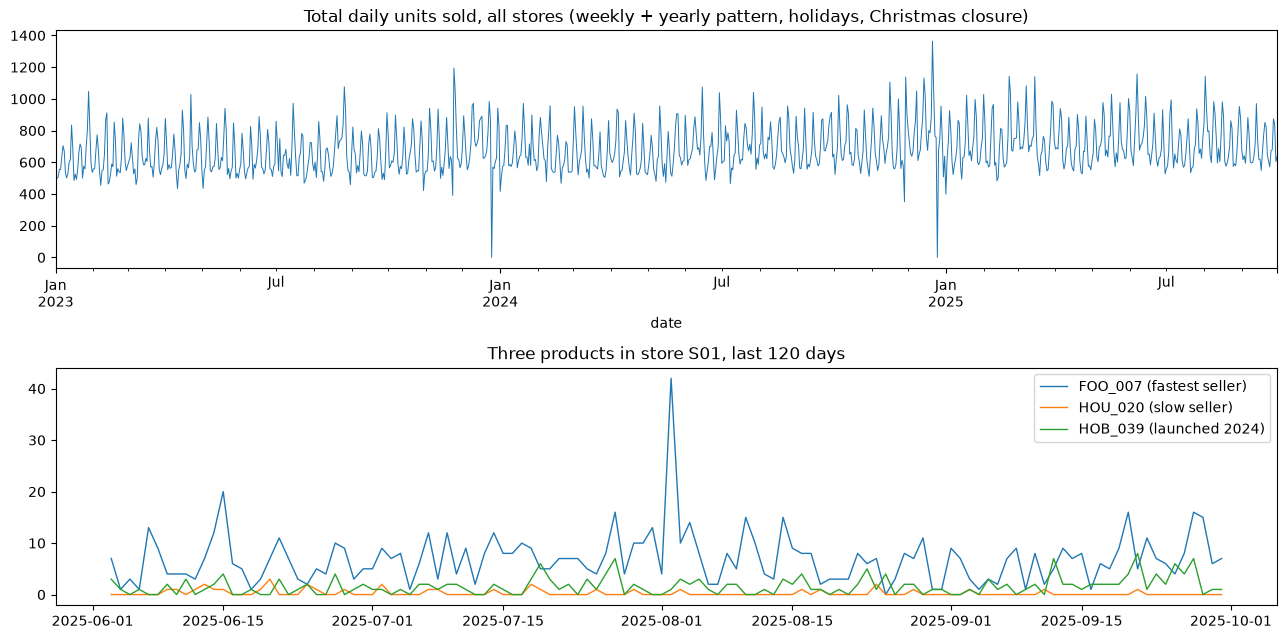

In [3]:
n_series = sales.groupby(KEYS).ngroups
print(f"{n_series} series | {sales['date'].min().date()} -> {sales['date'].max().date()}")
print(f"Share of zero-sales days: {(sales['sales'] == 0).mean():.1%}")
print(sales.groupby("category")["sales"].agg(mean_per_day="mean", zero_share=lambda s: (s == 0).mean()).round(2))

daily_total = sales.groupby("date")["sales"].sum()
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
daily_total.plot(ax=axes[0], lw=0.7)
axes[0].set_title("Total daily units sold, all stores (weekly + yearly pattern, holidays, Christmas closure)")
example = sales[(sales["store_id"] == "S01") & (sales["date"] > TODAY - pd.Timedelta(days=120))]
fastest = example.groupby("item_id")["sales"].mean().idxmax()            # best seller in this store
for item, role in [(fastest, "fastest seller"), ("HOU_020", "slow seller"), ("HOB_039", "launched 2024")]:
    s = example[example["item_id"] == item].set_index("date")["sales"]
    axes[1].plot(s.index, s.values, lw=1, label=f"{item} ({role})")
axes[1].set_title("Three products in store S01, last 120 days")
axes[1].legend(); plt.tight_layout(); plt.show()

**What we see:** a clear weekly rhythm (weekends are busy), yearly waves, spikes on Black Friday and before Christmas, and a
drop to zero on Christmas day (stores closed). At the product level the series are **noisy** and many are mostly zeros.
This is normal in retail and is why a 14-day product-level forecast will never be "precise": we must judge it against baselines.

---
## 4. Clean the data: build a complete daily panel

The most common silent bug in retail forecasting: **a missing row is not the same as zero sales.**

- If the POS export failed for store S03 on a Tuesday, there is **no row**. Filling it with `0` would teach the model
  "Tuesdays sometimes have zero sales" and drag forecasts down. We keep it as **missing** (`NaN`): it is not used as a training
  target, and lag features simply become `NaN` (LightGBM handles that).
- A product launched in March 2025 has no rows before March. Those days are **not** zeros either: we start the series at its first sale.
- Christmas day is a **real** zero (stores closed), and the calendar tells the model about it.

We also join the price plan and the calendar, so every row has everything the model needs.

In [4]:
def make_complete_panel(sales: pd.DataFrame, prices: pd.DataFrame, calendar: pd.DataFrame,
                        end_date: pd.Timestamp) -> pd.DataFrame:
    """One row per series per day from the series' first sale to `end_date`. Missing POS days stay NaN."""
    first_day = sales.groupby(KEYS)["date"].min().rename("first_day").reset_index()
    all_days = pd.DataFrame({"date": pd.date_range(sales["date"].min(), end_date, freq="D")})
    grid = first_day.merge(all_days, how="cross")                     # every series x every day ...
    grid = grid[grid["date"] >= grid["first_day"]].drop(columns="first_day")   # ... but only after launch
    panel = grid.merge(sales[KEYS + ["date", "sales"]], on=KEYS + ["date"], how="left")
    panel = panel.merge(prices, on=KEYS + ["date"], how="left")       # planned price + promo flag
    item_category = sales.groupby("item_id")["category"].first()
    panel["category"] = panel["item_id"].map(item_category)
    panel["event"] = panel["date"].map(calendar.groupby("date")["event"].first()).fillna("none")
    panel["is_missing_record"] = (panel["sales"].isna() & (panel["date"] <= sales["date"].max())).astype(int)
    return panel.sort_values(KEYS + ["date"]).reset_index(drop=True)


# The panel goes up to TODAY + horizon: future rows have NaN sales but KNOWN prices, promos and events
panel = make_complete_panel(sales, prices, calendar, end_date=TODAY + pd.Timedelta(days=CFG.horizon))
print(f"Complete panel: {len(panel):,} rows")
print(f"Missing POS records kept as NaN (not zero): {panel['is_missing_record'].sum():,} "
      f"({panel['is_missing_record'].mean():.1%} of history rows)")
print("Sales on Christmas day 2024 (stores closed):", panel.loc[panel["date"] == "2024-12-25", "sales"].sum())

Complete panel: 387,899 rows
Missing POS records kept as NaN (not zero): 4,442 (1.1% of history rows)
Sales on Christmas day 2024 (stores closed): 0.0


---
## 5. Validate the data

A forecast pipeline runs unattended every two weeks. If an upstream system breaks (negative quantities, duplicate rows,
a missing price plan), the job must **stop with a clear message** instead of silently ordering the wrong stock.

In [5]:
def validate_panel(panel: pd.DataFrame, today: pd.Timestamp, horizon: int) -> None:
    """Raise ValueError if the panel breaks the data contract."""
    required = set(KEYS + ["date", "sales", "sell_price", "on_promo", "category", "event"])
    if missing := required - set(panel.columns):
        raise ValueError(f"missing columns: {missing}")
    if panel.duplicated(KEYS + ["date"]).any():
        raise ValueError("duplicate (store, item, date) rows")
    if (panel["sales"] < 0).any():
        raise ValueError("negative sales found (returns must be handled upstream)")
    if panel["sell_price"].isna().any() or (panel["sell_price"] <= 0).any():
        raise ValueError("price plan has gaps or non-positive prices")
    future = panel[panel["date"] > today]
    if future["date"].nunique() != horizon:
        raise ValueError(f"price/calendar plan must cover exactly {horizon} future days")
    missing_share = panel.loc[panel["date"] <= today, "sales"].isna().mean()
    if missing_share > 0.05:                                     # more than 5% missing => upstream incident
        raise ValueError(f"{missing_share:.1%} of sales are missing: check the POS export")
    log.info("Data contract passed: %d rows, %.1f%% missing sales records", len(panel), 100 * missing_share)


validate_panel(panel, TODAY, CFG.horizon)
try:                                                             # show the contract catching a broken export
    validate_panel(panel.assign(sales=panel["sales"].where(panel.index % 50 != 0, -1)), TODAY, CFG.horizon)
except ValueError as err:
    print("Validation caught a problem ->", err)

2026-10-21 17:29:35,301 | INFO | Data contract passed: 387899 rows, 1.2% missing sales records


Validation caught a problem -> negative sales found (returns must be handled upstream)


---
## 6. Know your series: fast, erratic, intermittent and lumpy demand

Retailers classify products before forecasting, because **different products need different expectations**.
A standard scheme (Syntetos & Boylan, 2005) uses two numbers per series:

- **ADI** (Average Demand Interval): on average, how many days between two days with sales? ADI = 1 means it sells every day.
- **CV²** (squared coefficient of variation of the non-zero sales): how much the sale size varies when it does sell.

| | CV² < 0.49 (stable sizes) | CV² ≥ 0.49 (variable sizes) |
|---|---|---|
| **ADI < 1.32** (sells most days) | **smooth** | **erratic** |
| **ADI ≥ 1.32** (many zero days) | **intermittent** | **lumpy** |

We compute it on the year before the first backtest date, so the labels themselves contain no future information.

In [6]:
def classify_demand(panel: pd.DataFrame, start: pd.Timestamp, end: pd.Timestamp) -> pd.Series:
    """Syntetos-Boylan demand class per series, computed only on data in [start, end]."""
    window = panel[(panel["date"] >= start) & (panel["date"] <= end)].dropna(subset=["sales"])

    def one_series(s: pd.Series) -> str:
        nonzero = s[s > 0]
        if len(nonzero) < 2:
            return "lumpy"                                  # almost never sells
        adi = len(s) / len(nonzero)
        cv2 = (nonzero.std() / nonzero.mean()) ** 2
        if adi < 1.32:
            return "smooth" if cv2 < 0.49 else "erratic"
        return "intermittent" if cv2 < 0.49 else "lumpy"

    return window.groupby(KEYS)["sales"].apply(one_series).rename("demand_class")


first_origin = TODAY - pd.Timedelta(days=CFG.horizon * CFG.n_backtest_folds)
demand_class = classify_demand(panel, first_origin - pd.Timedelta(days=365), first_origin)
panel = panel.merge(demand_class.reset_index(), on=KEYS, how="left")
print(demand_class.value_counts())

demand_class
intermittent    239
erratic          77
smooth           57
lumpy            27
Name: count, dtype: int64


---
## 7. Honest evaluation: rolling-origin backtesting, baselines and metrics

### Rolling-origin backtesting
A random train/test split would let the model "see the future". Instead we pretend we are back in the past, on several
**forecast dates** (origins), and do exactly what production would have done on each date:

```
history ......................................|origin 1| 14 days |
history ...............................................|origin 2| 14 days |
history ........................................................|origin 3| 14 days |
history .................................................................|origin 4| 14 days |  <- TODAY
```

On each origin we train only on data **before** it and score the next 14 days. Averaging over 4 origins is much more reliable
than one split (one unlucky fortnight with a holiday can fool you). This is called *time series cross-validation* in Hyndman's
*Forecasting: Principles and Practice* and `backtesting` in skforecast.

### Baselines (what planners do today)
- **Naive**: repeat the last observed day.
- **Seasonal naive**: the same weekday last week (captures the weekly rhythm).
- **Moving average 28**: the average of the last 4 weeks (very strong for slow sellers).

### Metrics
- **MAE**: average absolute error in units.
- **WAPE** = sum of absolute errors / sum of actual sales. "We are off by X% of volume". Used by most retailers because it
  works with zeros (MAPE divides by zero on zero-sales days and explodes).
- **Bias** = (sum of forecasts - sum of actuals) / sum of actuals. Positive = we over-forecast (too much stock). A model can
  have a decent WAPE and still be biased; bias is what empties or overfills the warehouse.
- **MASE**: MAE divided by the in-sample MAE of a weekly seasonal naive forecast **of the same series**. Scale-free, so a slow
  and a fast product count equally. MASE < 1 means "better than the in-sample one-step seasonal naive" (a demanding bar for a
  14-day-ahead forecast). M5 used a squared version (RMSSE).

In [7]:
def backtest_origins(today: pd.Timestamp, horizon: int, n_folds: int) -> list:
    """Forecast dates in the past, oldest first, each followed by `horizon` scored days."""
    return [today - pd.Timedelta(days=horizon * k) for k in range(n_folds, 0, -1)]


def baseline_forecasts(panel: pd.DataFrame, origin: pd.Timestamp, horizon: int) -> pd.DataFrame:
    """Naive, seasonal-naive and 28-day moving-average forecasts made with data up to `origin` only."""
    past = panel[(panel["date"] <= origin) & panel["sales"].notna()]
    future = panel[(panel["date"] > origin) & (panel["date"] <= origin + pd.Timedelta(days=horizon))][KEYS + ["date"]].copy()
    last_value = past.groupby(KEYS)["sales"].last().rename("naive")
    ma28 = past[past["date"] > origin - pd.Timedelta(days=28)].groupby(KEYS)["sales"].mean().rename("ma28")
    last_week = past[past["date"] > origin - pd.Timedelta(days=7)].assign(dow=lambda d: d["date"].dt.dayofweek)
    snaive = last_week.groupby(KEYS + ["dow"])["sales"].mean().rename("snaive")
    future["dow"] = future["date"].dt.dayofweek
    future = future.join(last_value, on=KEYS).join(ma28, on=KEYS).join(snaive, on=KEYS + ["dow"])
    future["snaive"] = future["snaive"].fillna(future["ma28"])     # missing POS day last week -> fall back to MA
    return future.drop(columns="dow")


def mase_scale(panel: pd.DataFrame, origin: pd.Timestamp, days: int = 365) -> pd.Series:
    """Per-series in-sample MAE of the weekly seasonal naive forecast (the MASE denominator)."""
    hist = panel[(panel["date"] <= origin) & (panel["date"] > origin - pd.Timedelta(days=days))]
    diff = hist.groupby(KEYS)["sales"].diff(7).abs()
    return diff.groupby([hist["store_id"], hist["item_id"]]).mean().clip(lower=0.1).rename("mase_scale")


def forecast_metrics(df: pd.DataFrame, pred_col: str, actual_col: str = "sales") -> dict:
    """MAE, WAPE, bias and MASE for the rows in df (rows with missing actuals must be removed before)."""
    err = df[pred_col] - df[actual_col]
    per_series_mae = err.abs().groupby([df["store_id"], df["item_id"]]).mean()
    scale = df.groupby(KEYS)["mase_scale"].first()
    return {"MAE": err.abs().mean(),
            "WAPE": err.abs().sum() / df[actual_col].sum(),
            "bias": err.sum() / df[actual_col].sum(),
            "MASE": (per_series_mae / scale).mean()}


ORIGINS = backtest_origins(TODAY, CFG.horizon, CFG.n_backtest_folds)
print("Backtest origins:", [o.date().isoformat() for o in ORIGINS])

Backtest origins: ['2025-08-05', '2025-08-19', '2025-09-02', '2025-09-16']


---
## 8. Point-in-time correct features (and a leakage test)

A global model (one LightGBM model for all 400 series, the approach that dominated M5) learns from **features**: what happened
before, what day it is, whether there is a promotion. The golden rule:

> A feature for day *t* may only use information that would have been **available at the moment the forecast was made**.

On forecast date *T* we predict days *T+1 ... T+14*. For day *T+14* the most recent known sale is day *T*, i.e. **14 days
earlier**. So if every lag is **at least 14 days** (`lag_14`, `lag_21`, ...) and every rolling average is computed on sales
shifted by 14 days, the same features are valid for all 14 forecast days, and we never need a value we don't have.

Features we build (all per series):
- **lags**: sales 14, 21, ..., 49 days ago (multiples of 7 keep the same weekday),
- **rolling statistics** of the 14-day-shifted sales: mean over 7/28/56 days, standard deviation, share of zero days,
- **calendar**: weekday, day of month, month, day of year, event name,
- **price and promotion** (known in advance from the price plan): price, promo flag, price relative to its recent regular price,
- **identity**: store, item and product group as categorical features, so one model can learn their differences.

In [8]:
def _rolling(values: pd.Series, groups: list, window: int, how: str, min_periods: int) -> pd.Series:
    """Per-series rolling statistic, returned aligned with the original row index."""
    rolled = getattr(values.groupby(groups, observed=True, sort=False).rolling(window, min_periods=min_periods), how)()
    return rolled.reset_index(level=list(range(len(groups))), drop=True)


def build_features(panel: pd.DataFrame, lags=CFG.lags, windows=CFG.rolling_windows, roll_shift: int = CFG.horizon):
    """Add model features. Uses only sales at least `roll_shift` days old (point-in-time correct)."""
    df = panel.sort_values(KEYS + ["date"]).copy()
    groups = [df["store_id"], df["item_id"]]
    by_series = df.groupby(KEYS, observed=True, sort=False)["sales"]
    for lag in lags:
        df[f"lag_{lag}"] = by_series.shift(lag)                       # sales exactly `lag` days earlier
    shifted = by_series.shift(roll_shift)                              # the newest value we may use
    for w in windows:
        df[f"roll_mean_{w}"] = _rolling(shifted, groups, w, "mean", max(1, w // 2))
    df["roll_std_28"] = _rolling(shifted, groups, 28, "std", 14)
    is_zero = (shifted == 0).astype(float).where(shifted.notna())
    df["zero_share_28"] = _rolling(is_zero, groups, 28, "mean", 14)
    df["dow"] = df["date"].dt.dayofweek
    df["day_of_month"] = df["date"].dt.day
    df["month"] = df["date"].dt.month
    df["day_of_year"] = df["date"].dt.dayofyear
    regular_price = _rolling(df["sell_price"], groups, 90, "max", 1)   # prices are planned => no leakage
    df["price_ratio"] = df["sell_price"] / regular_price               # < 1 means discounted
    for col, cats in CATEGORY_LEVELS.items():                          # FIXED category lists (same at training & serving)
        df[col] = pd.Categorical(df[col], categories=cats)
    return df


CATEGORY_LEVELS = {"store_id": sorted(panel["store_id"].unique()), "item_id": sorted(panel["item_id"].unique()),
                   "category": ["FOODS", "HOBBIES", "HOUSEHOLD"],
                   "event": ["none"] + sorted(EVENT_LIFT)}
FEATURES = ([f"lag_{l}" for l in CFG.lags] + [f"roll_mean_{w}" for w in CFG.rolling_windows]
            + ["roll_std_28", "zero_share_28", "dow", "day_of_month", "month", "day_of_year",
               "sell_price", "on_promo", "price_ratio", "store_id", "item_id", "category", "event"])
print(len(FEATURES), "features:", FEATURES)

22 features: ['lag_14', 'lag_21', 'lag_28', 'lag_35', 'lag_42', 'lag_49', 'roll_mean_7', 'roll_mean_28', 'roll_mean_56', 'roll_std_28', 'zero_share_28', 'dow', 'day_of_month', 'month', 'day_of_year', 'sell_price', 'on_promo', 'price_ratio', 'store_id', 'item_id', 'category', 'event']


### Prove it: a leakage test

Talking about "no leakage" is easy; **testing** it is what professionals do. We build the features twice for the last
origin: once from the real data and once after replacing every sale **after** the origin with garbage.
If any feature of the 14 forecast days changes, a feature is peeking into the future.

In [9]:
def assert_point_in_time(panel: pd.DataFrame, origin: pd.Timestamp, horizon: int, **feature_kwargs) -> None:
    """Fails if features of the forecast days depend on sales after `origin`."""
    window = panel[panel["date"] > origin - pd.Timedelta(days=200)]            # recent data is enough
    garbage = window.copy()
    future_mask = garbage["date"] > origin
    garbage.loc[future_mask, "sales"] = 999_999                                # absurd future values
    test_days = lambda d: d[(d["date"] > origin) & (d["date"] <= origin + pd.Timedelta(days=horizon))]
    real = test_days(build_features(window, **feature_kwargs))[FEATURES].reset_index(drop=True)
    poisoned = test_days(build_features(garbage, **feature_kwargs))[FEATURES].reset_index(drop=True)
    pd.testing.assert_frame_equal(real, poisoned)                              # raises if anything differs
    print(f"PASSED  point-in-time test at origin {origin.date()}: future sales cannot influence the features")


assert_point_in_time(panel, ORIGINS[-1] - pd.Timedelta(days=CFG.horizon), CFG.horizon)

PASSED  point-in-time test at origin 2025-09-02: future sales cannot influence the features


---
## 9. A global LightGBM model, backtested

For each origin we:
1. **hide** all sales after the origin (set them to `NaN`), exactly like production on that date,
2. build features, train LightGBM on the last 365 days before the origin,
3. predict the next 14 days and compute the baselines from the same hidden data.

Why the **Tweedie** objective? Sales are non-negative counts with many zeros and occasional big days. Tweedie (a
compound Poisson-Gamma loss) fits that shape and was a favourite in M5. A plain squared-error loss works too but tends to
predict small negative or overly smooth values for slow sellers.

In [10]:
def train_lgbm(train_rows: pd.DataFrame, params: dict = None) -> lgb.LGBMRegressor:
    """Train one global LightGBM model on rows with a known target."""
    model = lgb.LGBMRegressor(**(params or CFG.lgbm_params))
    model.fit(train_rows[FEATURES], train_rows["sales"])
    return model


def run_backtest(panel: pd.DataFrame, origins: list) -> tuple:
    """Rolling-origin backtest. Returns (predictions table, model trained at the last origin)."""
    results, model = [], None
    for origin in origins:
        start = time.time()
        end = origin + pd.Timedelta(days=CFG.horizon)
        window = panel[(panel["date"] > origin - pd.Timedelta(days=CFG.train_window_days + 120)) & (panel["date"] <= end)]
        hidden = window.assign(sales=window["sales"].where(window["date"] <= origin))   # the future is unknown
        feats = build_features(hidden)
        train_rows = feats[(feats["date"] <= origin) & (feats["date"] > origin - pd.Timedelta(days=CFG.train_window_days))
                           & feats["sales"].notna()]
        test_rows = feats[feats["date"] > origin].copy()
        model = train_lgbm(train_rows)
        test_rows["lgbm"] = model.predict(test_rows[FEATURES]).clip(min=0)
        test_rows = test_rows.astype({"store_id": str, "item_id": str, "category": str})   # back to plain text keys
        fold = (test_rows[KEYS + ["date", "category", "demand_class", "lgbm", "sell_price"]]
                .merge(baseline_forecasts(hidden, origin, CFG.horizon), on=KEYS + ["date"])
                .merge(window[KEYS + ["date", "sales"]], on=KEYS + ["date"])           # attach the real outcome
                .join(mase_scale(hidden, origin), on=KEYS))
        fold["origin"], fold["horizon_day"] = origin, (fold["date"] - origin).dt.days
        results.append(fold)
        log.info("origin %s: trained on %d rows in %.0fs", origin.date(), len(train_rows), time.time() - start)
    return pd.concat(results, ignore_index=True), model


backtest, last_fold_model = run_backtest(panel, ORIGINS)
scored = backtest.dropna(subset=["sales"])            # missing POS days cannot be scored
print(f"{len(scored):,} scored forecasts ({backtest['sales'].isna().sum()} missing actuals skipped)")

2026-10-21 17:31:01,511 | INFO | origin 2025-08-05: trained on 142114 rows in 81s


2026-10-21 17:31:48,639 | INFO | origin 2025-08-19: trained on 142354 rows in 47s


2026-10-21 17:32:37,818 | INFO | origin 2025-09-02: trained on 142670 rows in 49s


2026-10-21 17:33:28,016 | INFO | origin 2025-09-16: trained on 142929 rows in 50s


22,160 scored forecasts (240 missing actuals skipped)


In [11]:
MODELS = ["naive", "snaive", "ma28", "lgbm"]
rows = []
for name in MODELS:
    per_fold = scored.groupby("origin").apply(lambda d: forecast_metrics(d, name)["WAPE"])
    overall = forecast_metrics(scored, name)
    rows.append({"model": name, **{k: round(v, 3) for k, v in overall.items()},
                 "WAPE_std_over_folds": round(per_fold.std(), 3)})
leaderboard = pd.DataFrame(rows).set_index("model").sort_values("WAPE")
leaderboard

,MAE,WAPE,bias,MASE,WAPE_std_over_folds
model,,,,,
lgbm,1.206,0.671,-0.014,0.759,0.003
ma28,1.304,0.726,0.022,0.800,0.017
naive,1.627,0.905,-0.091,0.954,0.065
snaive,1.702,0.947,0.059,0.992,0.056


**How to read the leaderboard** (look at the printed numbers above):
- The **naive** forecast (repeat yesterday) is the worst: one day is a very noisy estimate for a product.
- **Seasonal naive** knows the weekday but copies last week's noise, so it is still weak at product level.
- The **28-day moving average** is a surprisingly tough baseline: it averages away the noise. Many retailers live with it.
- **LightGBM** is best on every metric: WAPE 0.671 vs 0.726 for the moving average (about 8% less error), MASE 0.76 vs 0.80.
  That improvement is the value the project adds. It is real: the gap (0.055) is much larger than the fold-to-fold
  standard deviation of the WAPE (0.003 for LightGBM, 0.017 for the moving average).
- Product-level WAPE looks high (tens of percent). That is **normal** for daily store x product data with many slow sellers.
  The same forecast summed to a weekly store total is far more accurate (see section 10).

---
## 10. Error analysis: per product group, per demand type, per horizon day

An average hides problems. Planners want to know **where** the forecast is good and where they should stay careful.

In [12]:
def metrics_by(df: pd.DataFrame, group: str, models=("ma28", "lgbm")) -> pd.DataFrame:
    """WAPE and bias of each model per group (e.g. per product category)."""
    out = {}
    for name in models:
        m = df.groupby(group).apply(lambda d: pd.Series(forecast_metrics(d, name)))
        out[(name, "WAPE")], out[(name, "bias")] = m["WAPE"], m["bias"]
    out[("volume", "share")] = df.groupby(group)["sales"].sum() / df["sales"].sum()
    return pd.DataFrame(out).round(3)


print("Per product group:")
display(metrics_by(scored, "category"))
print("Per demand type (Syntetos-Boylan class):")
display(metrics_by(scored, "demand_class"))

# Aggregation makes forecasts look much better: the same forecasts summed per store and ISO week
weekly = scored.assign(week=scored["date"].dt.isocalendar().week).groupby(["store_id", "week", "origin"])[["sales", "lgbm", "ma28"]].sum()
print("WAPE of the SAME forecasts at store x week level: "
      f"lgbm {(weekly['lgbm'] - weekly['sales']).abs().sum() / weekly['sales'].sum():.3f} | "
      f"ma28 {(weekly['ma28'] - weekly['sales']).abs().sum() / weekly['sales'].sum():.3f}")

Per product group:


ma28          lgbm        volume
            WAPE   bias   WAPE   bias  share
category                                    
FOODS      0.709  0.079  0.648 -0.005  0.519
HOBBIES    0.689 -0.077  0.647 -0.064  0.283
HOUSEHOLD  0.823  0.015  0.769  0.036  0.198

Per demand type (Syntetos-Boylan class):


ma28          lgbm        volume
               WAPE   bias   WAPE   bias  share
demand_class                                   
erratic       0.625  0.029  0.558 -0.027  0.404
intermittent  0.937 -0.012  0.904  0.000  0.285
lumpy         0.847 -0.023  0.764 -0.018  0.054
smooth        0.626  0.059  0.574 -0.007  0.258

WAPE of the SAME forecasts at store x week level: lgbm 0.062 | ma28 0.086

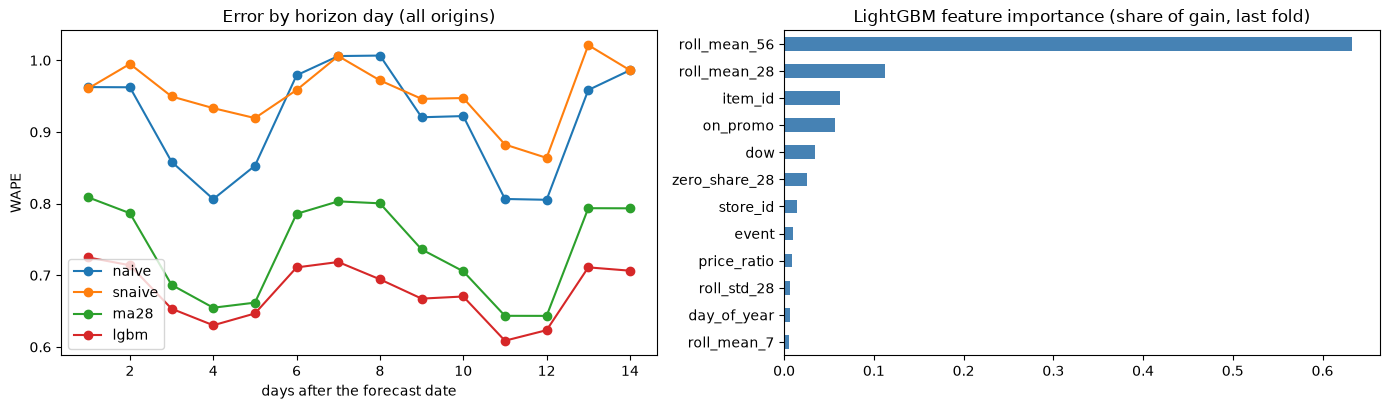

Top 6 features by share of gain: {'roll_mean_56': 0.632, 'roll_mean_28': 0.113, 'item_id': 0.062, 'on_promo': 0.057, 'dow': 0.035, 'zero_share_28': 0.026}


In [13]:
by_day = scored.groupby("horizon_day").apply(
    lambda d: pd.Series({m: (d[m] - d["sales"]).abs().sum() / d["sales"].sum() for m in MODELS}))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
by_day.plot(ax=axes[0], marker="o")
axes[0].set_xlabel("days after the forecast date"); axes[0].set_ylabel("WAPE")
axes[0].set_title("Error by horizon day (all origins)")
importance = pd.Series(last_fold_model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
(importance / importance.sum()).tail(12).plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("LightGBM feature importance (share of gain, last fold)")
plt.tight_layout(); plt.show()
print("Top 6 features by share of gain:", (importance / importance.sum()).sort_values(ascending=False).head(6).round(3).to_dict())

**What the plots tell us:**
- Errors vary by horizon day mostly because of the **weekday** (weekends sell more, so absolute errors are bigger) and the
  holiday (Labor Day) inside one fold, not because day 14 is "further away": our lag-14 model uses the same information for all 14 days.
- The importance chart (and the printed top 6) shows what the model relies on: by far the **rolling averages** (the 56-day
  mean alone carries most of the gain: "how much does this product usually sell here"), then the **item identity**, the
  **promotion flag**, the share of zero days and the **weekday**. That matches the business story. If an ID-like or
  date-like feature dominated, we would suspect overfitting or leakage.
- Check the per-group tables: intermittent and lumpy products have the **highest WAPE** for every model. For those products
  the business should rely more on safety stock (section 13) than on a precise point forecast.

---
## 11. Recursive vs direct multi-step forecasting

There are three ways to forecast 14 days with a machine-learning model:

| Strategy | How | Pros | Cons |
|---|---|---|---|
| **Recursive** | Train with `lag_1`, `lag_2`, ...; predict day 1, feed the prediction back as "yesterday", predict day 2, ... | One model, uses the freshest data | Errors **compound**; prediction is a slow loop; training/serving mismatch (trained on real lags, served on predicted lags) |
| **Direct (one model per day)** | 14 models, model *h* uses lags >= *h* | No compounding | 14 models to train, store and monitor |
| **Direct, shared lags >= horizon** (what we use) | One model, every lag >= 14 days | Simple, fast, no loop, no compounding | Ignores the most recent 13 days for the first forecast days |

Many M5 solutions used recursive models with lag 1..7; others used the "lags >= 28" trick. Neither always wins, so we **test
both on the same fold** instead of guessing.

In [14]:
RECURSIVE_LAGS, RECURSIVE_WINDOWS = (1, 2, 3, 7, 14, 21, 28), (7, 28, 56)
REC_FEATURES = ([f"lag_{l}" for l in RECURSIVE_LAGS] + [f"roll_mean_{w}" for w in RECURSIVE_WINDOWS]
                + [f for f in FEATURES if not f.startswith(("lag_", "roll_mean_"))])


def recursive_forecast(panel: pd.DataFrame, origin: pd.Timestamp) -> pd.DataFrame:
    """Train a lag-1 model and forecast 14 days one step at a time, feeding predictions back in."""
    window = panel[(panel["date"] > origin - pd.Timedelta(days=CFG.train_window_days + 120))
                   & (panel["date"] <= origin + pd.Timedelta(days=CFG.horizon))]
    work = window.assign(sales=window["sales"].where(window["date"] <= origin))
    feats = build_features(work, lags=RECURSIVE_LAGS, windows=RECURSIVE_WINDOWS, roll_shift=1)
    train_rows = feats[(feats["date"] <= origin) & (feats["date"] > origin - pd.Timedelta(days=CFG.train_window_days))
                       & feats["sales"].notna()]
    model = lgb.LGBMRegressor(**CFG.lgbm_params).fit(train_rows[REC_FEATURES], train_rows["sales"])
    recent = work[work["date"] > origin - pd.Timedelta(days=90)].copy()       # enough history for lag 28 / roll 56
    for step in range(1, CFG.horizon + 1):                                   # the recursive loop
        day = origin + pd.Timedelta(days=step)
        day_feats = build_features(recent, lags=RECURSIVE_LAGS, windows=RECURSIVE_WINDOWS, roll_shift=1)
        rows = day_feats[day_feats["date"] == day]
        preds = model.predict(rows[REC_FEATURES]).clip(min=0)
        recent.loc[rows.index, "sales"] = preds                               # prediction becomes "history"
    return recent[recent["date"] > origin][KEYS + ["date", "sales"]].rename(columns={"sales": "recursive"})


start = time.time()
last_origin = ORIGINS[-1]
rec = recursive_forecast(panel, last_origin)
compare = scored[scored["origin"] == last_origin].merge(rec, on=KEYS + ["date"])
print(f"Recursive forecast took {time.time() - start:.0f}s (training + 14 feature rebuilds)")
comparison = pd.DataFrame({m: forecast_metrics(compare, m) for m in ["ma28", "lgbm", "recursive"]}).T.round(3)
comparison.index = ["moving average 28", "direct (lags >= 14)", "recursive (lags >= 1)"]
display(comparison)
day_wape = compare.groupby("horizon_day").apply(
    lambda d: pd.Series({m: (d[m] - d["sales"]).abs().sum() / d["sales"].sum() for m in ["lgbm", "recursive"]}))
print("WAPE by horizon day (last fold):")
print(day_wape.round(3).T.to_string())

Recursive forecast took 62s (training + 14 feature rebuilds)


,MAE,WAPE,bias,MASE
moving average 28,1.254,0.702,-0.014,0.780
direct (lags >= 14),1.204,0.673,-0.009,0.756
recursive (lags >= 1),1.204,0.673,-0.007,0.759


WAPE by horizon day (last fold):
horizon_day     1      2      3      4      5      6      7      8      9      10     11     12     13     14
lgbm         0.694  0.663  0.631  0.628  0.688  0.731  0.692  0.682  0.705  0.700  0.631  0.619  0.726  0.695
recursive    0.693  0.660  0.627  0.627  0.685  0.734  0.686  0.688  0.706  0.695  0.637  0.621  0.723  0.700


Read the two tables above: on our data the two strategies are **practically identical** (the WAPE differs in the third
decimal, and the per-day numbers go back and forth). Yesterday's sales of one product in one store are mostly **noise**, so
knowing them barely helps, and on later days the recursive model's inputs are its own predictions anyway.
When accuracy is a tie, look at the **cost side**: the recursive approach needs a feature rebuild and a prediction call per
day, and its training data (real lags) differs from its serving data (predicted lags). Teams therefore choose the simpler
direct model unless the recursive one is **clearly** better on several folds. Recursive models tend to help more for
aggregated, smoother series (e.g. store totals), where yesterday really says something about tomorrow.
(Exercise 2 asks you to run the comparison on all folds.)

---
## 12. Quantile forecasts: how uncertain are we?

A point forecast says "we expect 6 units". Replenishment needs more: "there is a 90% chance demand will be at most 11".
LightGBM can learn a **quantile** directly with `objective="quantile"` (the pinball loss, see `09_probabilistic_forecasting.ipynb`).
We train a 10% and a 90% quantile model on the last fold and check **coverage**: about 90% of actual values should be
below the P90 forecast, and about 80% should fall inside [P10, P90]. An interval that claims 80% but covers 60% is dangerous.

In [15]:
def train_quantile_models(panel: pd.DataFrame, origin: pd.Timestamp, quantiles=(0.1, 0.9)) -> tuple:
    """Train one LightGBM per quantile with data up to origin; return (models, features of the next 14 days)."""
    window = panel[(panel["date"] > origin - pd.Timedelta(days=CFG.train_window_days + 120))
                   & (panel["date"] <= origin + pd.Timedelta(days=CFG.horizon))]
    feats = build_features(window.assign(sales=window["sales"].where(window["date"] <= origin)))
    train_rows = feats[(feats["date"] <= origin) & (feats["date"] > origin - pd.Timedelta(days=CFG.train_window_days))
                       & feats["sales"].notna()]
    models = {}
    for q in quantiles:
        params = {**CFG.lgbm_params, "objective": "quantile", "alpha": q, "n_estimators": 150}
        params.pop("tweedie_variance_power")
        models[q] = lgb.LGBMRegressor(**params).fit(train_rows[FEATURES], train_rows["sales"])
    return models, feats[feats["date"] > origin]


q_models, last_test_feats = train_quantile_models(panel, last_origin)
qcols = last_test_feats[KEYS + ["date"]].astype(str).assign(date=last_test_feats["date"],
                                               p10=q_models[0.1].predict(last_test_feats[FEATURES]).clip(min=0),
                                               p90=q_models[0.9].predict(last_test_feats[FEATURES]).clip(min=0))
last_fold = scored[scored["origin"] == last_origin].merge(qcols, on=KEYS + ["date"])
coverage = last_fold.groupby("demand_class").apply(lambda d: pd.Series({
    "share_below_P90 (target 0.90)": (d["sales"] <= d["p90"]).mean(),
    "inside_P10_P90 (target 0.80)": ((d["sales"] >= d["p10"]) & (d["sales"] <= d["p90"])).mean(),
    "avg_interval_width": (d["p90"] - d["p10"]).mean()})).round(3)
coverage.loc["ALL"] = [(last_fold["sales"] <= last_fold["p90"]).mean(),
                       ((last_fold["sales"] >= last_fold["p10"]) & (last_fold["sales"] <= last_fold["p90"])).mean(),
                       (last_fold["p90"] - last_fold["p10"]).mean()]
coverage.round(3)

,share_below_P90 (target 0.90),inside_P10_P90 (target 0.80),avg_interval_width
demand_class,,,
erratic,0.880,0.795,6.486
intermittent,0.896,0.891,2.287
lumpy,0.870,0.865,3.217
smooth,0.899,0.829,5.811
ALL,0.892,0.862,3.663


Compare each coverage number with its target. Two lessons usually show up with count data:
- For slow sellers the P10 is often 0, and actual sales of 0 count as "inside", so interval coverage can look fine (or too high)
  while being uninformative.
- Daily quantiles are not the end of the story. Replenishment needs the uncertainty of the **14-day total**, and you
  **cannot** add up daily P90s to get the P90 of the total (good and bad days partly cancel out). The next section shows the
  cost of that mistake and a better way.

---
## 13. From forecasts to orders: the cost of over- and under-stock

### The newsvendor rule (the most useful formula in inventory planning)
Let `cu` = cost of having **one unit too few** (lost margin) and `co` = cost of **one unit too many** (waste, holding).
The order quantity that minimises the expected cost is the **quantile** of demand at the **critical ratio**:

$$\tau = \frac{c_u}{c_u + c_o}$$

- FOODS: lost margin 30% of price, waste 25% -> tau = 0.55 (spoilage is expensive: order close to the median).
- HOUSEHOLD: 35% vs 4% -> tau = 0.90 (keeping extra stock is cheap: protect availability).
- HOBBIES: 40% vs 5% -> tau = 0.89.

### Four ordering policies, scored on the last fold (never used to calibrate anything)
For each store x product we order once for the 14 days (simplification: no starting stock, delivery before day 1).

1. **Planner rule (status quo)**: order what we sold in the last 14 days.
2. **Point forecast**: order the sum of the 14 daily LightGBM forecasts (the expected demand).
3. **Sum of daily P90** (a common shortcut): ignores the cost structure and over-protects.
4. **Critical-ratio order**: point forecast x a safety factor learned from the **earlier backtest folds**: for each product
   group and demand class we look at how actual 14-day demand compared with the forecast in the past
   (the ratio `actual / forecast`) and take its tau-quantile. This is a simple form of **conformal calibration**.

In [16]:
def critical_ratio(category: str) -> float:
    """Newsvendor optimal service level for a product group."""
    cu, co = CFG.underage_rate[category], CFG.overage_rate[category]
    return cu / (cu + co)


def fortnight_totals(df: pd.DataFrame, cols: list) -> pd.DataFrame:
    """Sum actuals and forecasts per series and origin over the scored days."""
    agg = {c: "sum" for c in ["sales"] + cols}
    agg.update({"category": "first", "demand_class": "first", "sell_price": "mean"})
    return df.groupby(KEYS + ["origin"]).agg(agg).reset_index()


def learn_safety_factors(history: pd.DataFrame) -> pd.DataFrame:
    """tau-quantile of (actual+1)/(forecast+1) per (category, demand class), from past backtest folds."""
    ratio = (history["sales"] + 1) / (history["lgbm"] + 1)
    factors = (history.assign(ratio=ratio).groupby(["category", "demand_class"])
               .apply(lambda d: d["ratio"].quantile(critical_ratio(d.name[0]))).rename("safety_factor"))
    return factors.reset_index()


def order_cost(order: pd.Series, demand: pd.Series, category: pd.Series, price: pd.Series) -> pd.DataFrame:
    """$ cost of an order given realised demand: lost margin for shortages, waste/holding for leftovers."""
    short, left = (demand - order).clip(lower=0), (order - demand).clip(lower=0)
    cu = category.map(CFG.underage_rate) * price
    co = category.map(CFG.overage_rate) * price
    return pd.DataFrame({"shortage_cost": short * cu, "leftover_cost": left * co,
                         "units_short": short, "units_left": left})


calibration_folds = fortnight_totals(scored[scored["origin"] < last_origin], ["lgbm"])
SAFETY = learn_safety_factors(calibration_folds)

test_totals = fortnight_totals(last_fold, ["lgbm", "p90"])
recent_14 = (panel[(panel["date"] > last_origin - pd.Timedelta(days=CFG.horizon)) & (panel["date"] <= last_origin)]
             .groupby(KEYS)["sales"].mean() * CFG.horizon).rename("last_14_days")   # mean x 14 handles missing days
test_totals = test_totals.join(recent_14, on=KEYS).merge(SAFETY, on=["category", "demand_class"], how="left")
n_days = last_fold.groupby(KEYS)["date"].count().rename("n_days")                   # scored days (missing POS days removed)
test_totals = test_totals.join(n_days, on=KEYS)

policies = {
    "1. planner: last 14 days": np.round(test_totals["last_14_days"] * test_totals["n_days"] / CFG.horizon),
    "2. point forecast": np.round(test_totals["lgbm"]),
    "3. sum of daily P90": np.round(test_totals["p90"]),
    "4. critical-ratio order": np.round(((test_totals["lgbm"] + 1) * test_totals["safety_factor"] - 1).clip(lower=0)),
}
summary = []
for name, order in policies.items():
    c = order_cost(order, test_totals["sales"], test_totals["category"], test_totals["sell_price"])
    summary.append({"policy": name, "total_cost_$": c["shortage_cost"].sum() + c["leftover_cost"].sum(),
                    "shortage_cost_$": c["shortage_cost"].sum(), "leftover_cost_$": c["leftover_cost"].sum(),
                    "fill_rate": 1 - c["units_short"].sum() / test_totals["sales"].sum(),
                    "units_ordered": order.sum()})
order_summary = pd.DataFrame(summary).set_index("policy").round(3)
order_summary

,total_cost_$,shortage_cost_$,leftover_cost_$,fill_rate,units_ordered
policy,,,,,
1. planner: last 14 days,9682.696,7290.906,2391.789,0.856,9537.0
2. point forecast,7874.631,5904.133,1970.498,0.897,9703.0
3. sum of daily P90,24418.647,0.000,24418.647,1.000,20988.0
4. critical-ratio order,5678.979,2515.463,3163.517,0.949,11631.0


In [17]:
# Where does the money go? Cost per product group for the status quo vs the critical-ratio policy
per_group = {}
for name in ["1. planner: last 14 days", "4. critical-ratio order"]:
    c = order_cost(policies[name], test_totals["sales"], test_totals["category"], test_totals["sell_price"])
    per_group[name] = (c["shortage_cost"] + c["leftover_cost"]).groupby(test_totals["category"]).sum()
per_group = pd.DataFrame(per_group).round(0)
per_group["saving_%"] = (1 - per_group["4. critical-ratio order"] / per_group["1. planner: last 14 days"]).mul(100).round(1)
print("Total cost by product group ($, one 14-day cycle, 400 store-products):")
per_group

Total cost by product group ($, one 14-day cycle, 400 store-products):


,1. planner: last 14 days,4. critical-ratio order,saving_%
category,,,
FOODS,4766.0,3806.0,20.1
HOBBIES,2894.0,1245.0,57.0
HOUSEHOLD,2023.0,628.0,69.0


**What this shows (check against the numbers above):**
- The **point forecast** is more accurate than the planner rule, but ordering the expected value ignores that a missing unit of
  HOUSEHOLD costs ~9x more than a leftover one. Accuracy alone does not minimise cost.
- **Summing daily P90s** over-orders: it buys far more units than needed because the 14-day total is much less uncertain than
  14 separate worst cases. It may look "safe" (high fill rate), but the leftover cost is large.
- The **critical-ratio order** uses the economics per product group and a safety factor calibrated on past folds. It gives
  the lowest total cost, roughly 40% below the planner rule, with a higher fill rate. Notice in the per-group table that the
  saving is largest for HOUSEHOLD and HOBBIES (cheap to hold, so it pays to protect availability) and smallest for FOODS,
  where spoilage makes extra stock expensive and the best order stays close to the median.
- This is a simplification: real systems also handle starting stock, lead times, case-pack sizes, shelf capacity and minimum
  display quantities. The core idea, **forecast distribution + cost ratio = order quantity**, stays the same.

---
## 14. Train the final model and save it with metadata

The backtest told us **how good** the approach is. For production we retrain on **all** data up to today, using the same recipe,
and save one **bundle**: the model, the feature list, the category levels, the safety factors, the config and the backtest
metrics. Six months later anyone can see what was deployed and how good it was expected to be.

We save to a temporary folder (in a real project: `models/demand_forecast/v1/` or a model registry such as MLflow).

In [18]:
start = time.time()
final_window = panel[panel["date"] > TODAY - pd.Timedelta(days=CFG.train_window_days + 120)]
final_feats = build_features(final_window)
final_train = final_feats[(final_feats["date"] <= TODAY) & (final_feats["date"] > TODAY - pd.Timedelta(days=CFG.train_window_days))
                          & final_feats["sales"].notna()]
final_model = train_lgbm(final_train)
log.info("Final model trained on %d rows in %.0fs", len(final_train), time.time() - start)

# Safety factors for production: learned from ALL backtest folds (more data than the evaluation above used)
final_safety = learn_safety_factors(fortnight_totals(scored, ["lgbm"]))

bundle = {
    "model": final_model,
    "features": FEATURES,
    "category_levels": CATEGORY_LEVELS,
    "safety_factors": final_safety,
    "config": asdict(CFG),
    "trained_until": TODAY.isoformat(),
    "backtest_metrics": leaderboard.reset_index().to_dict(orient="records"),
}
ARTIFACT_DIR = Path(tempfile.mkdtemp(prefix="demand_forecast_"))   # in real life: models/demand_forecast/v1/
joblib.dump(bundle, ARTIFACT_DIR / "bundle.joblib")
metadata = {k: v for k, v in bundle.items() if k not in ("model", "safety_factors", "category_levels")}
metadata.update({"saved_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                 "lightgbm_version": lgb.__version__, "n_training_rows": int(len(final_train))})
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str))
for f in ARTIFACT_DIR.iterdir():
    print(f"{f.name:15s} {f.stat().st_size / 1024:8.1f} KB")

2026-10-21 17:35:13,732 | INFO | Final model trained on 142988 rows in 8s


bundle.joblib      689.2 KB
metadata.json        2.0 KB


---
## 15. A forecast function with input validation

This is the function the scheduled job (Airflow, Prefect, cron, see `15_MLOps/03_pipeline_orchestration/`) calls every two weeks.
It takes the **raw** tables (recent sales history and the price plan for the next 14 days) and returns daily forecasts plus an
order quantity per store and product. It checks its inputs first, because a forecast built on broken data is worse than none.

In [19]:
MIN_HISTORY_DAYS = max(CFG.lags) + max(CFG.rolling_windows)       # enough days to compute every feature


def forecast_next_14_days(bundle: dict, sales_history: pd.DataFrame, price_plan: pd.DataFrame,
                          calendar: pd.DataFrame, origin: pd.Timestamp) -> pd.DataFrame:
    """Daily forecasts for origin+1..origin+14 and one order quantity per store x product."""
    horizon = bundle["config"]["horizon"]
    # ---- 1. input validation ----
    needed = {"date", "store_id", "item_id", "category", "sales"}
    if missing := needed - set(sales_history.columns):
        raise ValueError(f"sales_history is missing columns {missing}")
    if sales_history["date"].max() != origin:
        raise ValueError(f"sales_history must end at the forecast date {origin.date()}, got {sales_history['date'].max().date()}")
    if (sales_history["date"].max() - sales_history["date"].min()).days < MIN_HISTORY_DAYS:
        raise ValueError(f"need at least {MIN_HISTORY_DAYS} days of history")
    if (sales_history["sales"] < 0).any():
        raise ValueError("negative sales in history")
    unknown_items = set(sales_history["item_id"]) - set(bundle["category_levels"]["item_id"])
    if unknown_items:
        log.warning("new items %s are unknown to the model: they get no item-specific effect", unknown_items)
    future_days = pd.date_range(origin + pd.Timedelta(days=1), periods=horizon)
    plan = price_plan[price_plan["date"].isin(future_days)]
    series = sales_history[["store_id", "item_id"]].drop_duplicates()
    if len(plan) != len(series) * horizon:
        raise ValueError("price_plan must contain every store x item for each of the next 14 days")
    # ---- 2. build features exactly as in training ----
    recent = sales_history[sales_history["date"] > origin - pd.Timedelta(days=MIN_HISTORY_DAYS + 30)]
    work = make_complete_panel(recent, price_plan, calendar, end_date=future_days[-1])
    feats = build_features(work)
    feats = feats[feats["date"] > origin].copy()
    # ---- 3. predict and turn into orders ----
    feats["forecast"] = bundle["model"].predict(feats[bundle["features"]]).clip(min=0)
    classes = classify_demand(work, origin - pd.Timedelta(days=MIN_HISTORY_DAYS), origin).reset_index()
    totals = (feats.groupby(KEYS, observed=True).agg(forecast_14d=("forecast", "sum"), category=("category", "first"))
              .reset_index().astype({"store_id": str, "item_id": str, "category": str})
              .merge(classes, on=KEYS, how="left")
              .merge(bundle["safety_factors"], on=["category", "demand_class"], how="left"))
    totals["safety_factor"] = totals["safety_factor"].fillna(1.0)
    totals["order_qty"] = np.round(((totals["forecast_14d"] + 1) * totals["safety_factor"] - 1).clip(lower=0)).astype(int)
    daily = feats[KEYS + ["date", "forecast"]].astype({"store_id": str, "item_id": str})
    return daily.merge(totals[KEYS + ["forecast_14d", "order_qty"]], on=KEYS)


service_bundle = joblib.load(ARTIFACT_DIR / "bundle.joblib")       # simulates a fresh job start-up
result = forecast_next_14_days(service_bundle, sales, prices, calendar, origin=TODAY)
print(f"{len(result):,} daily forecasts | total order: {result.drop_duplicates(KEYS)['order_qty'].sum():,} units")
result.drop_duplicates(KEYS).sort_values("forecast_14d", ascending=False).head(5)

5,600 daily forecasts | total order: 12,037 units


,store_id,item_id,date,forecast,forecast_14d,order_qty
1988,S04,HOB_034,2025-10-01,10.214459,169.935787,236
1778,S04,FOO_007,2025-10-01,9.797279,154.895626,159
4788,S09,HOB_034,2025-10-01,7.461263,126.729093,166
4578,S09,FOO_007,2025-10-01,7.066870,126.009912,129
1218,S03,FOO_007,2025-10-01,7.831409,125.884021,129


In [20]:
# Bad inputs must fail loudly with a clear message
bad_cases = {
    "history ends too early": lambda: forecast_next_14_days(service_bundle, sales[sales["date"] < TODAY], prices, calendar, TODAY),
    "price plan has a gap": lambda: forecast_next_14_days(
        service_bundle, sales, prices[~((prices["date"] == TODAY + pd.Timedelta(days=3)) & (prices["store_id"] == "S02"))],
        calendar, TODAY),
    "negative sales": lambda: forecast_next_14_days(service_bundle, sales.assign(sales=sales["sales"].replace(0, -1)), prices, calendar, TODAY),
}
for case, call in bad_cases.items():
    try:
        call()
        print(f"{case:25s} -> NOT caught (bug!)")
    except ValueError as err:
        print(f"{case:25s} -> rejected: {err}")

history ends too early    -> rejected: sales_history must end at the forecast date 2025-09-30, got 2025-09-29


price plan has a gap      -> rejected: price_plan must contain every store x item for each of the next 14 days
negative sales            -> rejected: negative sales in history


---
## 16. Monitoring: detect when the forecast goes wrong after go-live

After deployment, the world keeps changing: a competitor opens, a product gets a new package, a store is renovated.
The model will not tell you; **monitoring** must. A simple, effective setup used by many retailers:

1. Every week, compare last week's forecasts with the actual sales (they arrive from the POS system).
2. Track **WAPE** and **bias** per store (and per product group).
3. **Alert** when the bias of a store is beyond +/-15% (systematically wrong in one direction), or when WAPE is far
   above what the backtest promised.

Below we simulate 8 weeks after go-live. Each Tuesday the job forecasts with the saved model, and one week later we score it.
(Unknown to us, in the simulator store **S07** loses 35% of its demand from 22 October 2025 because a competitor opened.)

In [21]:
monitor_rows = []
for week in range(8):
    origin = TODAY + pd.Timedelta(days=7 * week)
    history = pd.concat([sales, future_actuals[future_actuals["date"] <= origin]])     # actuals known at that date
    fc = forecast_next_14_days(service_bundle, history, prices, calendar, origin)
    first_week = fc[fc["date"] <= origin + pd.Timedelta(days=7)]                     # score the first 7 days
    scored_week = first_week.merge(future_actuals[KEYS + ["date", "sales"]], on=KEYS + ["date"])  # missing POS days drop out
    per_store = scored_week.groupby("store_id").apply(lambda d: pd.Series({
        "WAPE": (d["forecast"] - d["sales"]).abs().sum() / d["sales"].sum(),
        "bias": (d["forecast"] - d["sales"]).sum() / d["sales"].sum()}))
    monitor_rows.append(per_store.assign(week_start=(origin + pd.Timedelta(days=1)).date()).reset_index())
monitor = pd.concat(monitor_rows, ignore_index=True)

BIAS_ALERT, BACKTEST_WAPE = 0.15, leaderboard.loc["lgbm", "WAPE"]
monitor["alert"] = np.where(monitor["bias"].abs() > BIAS_ALERT, "BIAS ALERT", "ok")
bias_table = monitor.pivot(index="store_id", columns="week_start", values="bias").round(2)
print(f"Weekly bias per store (alert if |bias| > {BIAS_ALERT:.0%}); backtest WAPE was {BACKTEST_WAPE:.3f}")
display(bias_table)
print(monitor[monitor["alert"] != "ok"][["week_start", "store_id", "bias", "WAPE"]].round(3).to_string(index=False))

Weekly bias per store (alert if |bias| > 15%); backtest WAPE was 0.671


week_start,2025-10-01,2025-10-08,2025-10-15,2025-10-22,2025-10-29,2025-11-05,2025-11-12,2025-11-19
store_id,,,,,,,,
S01,-0.12,-0.01,-0.16,-0.03,-0.01,-0.11,0.01,0.07
S02,0.10,-0.07,-0.15,-0.03,0.17,-0.05,0.05,-0.06
S03,-0.05,0.10,-0.06,-0.08,-0.18,-0.03,-0.11,-0.01
S04,-0.01,-0.02,-0.03,-0.07,-0.05,-0.09,-0.11,-0.08
S05,0.04,0.03,-0.06,0.03,0.14,-0.06,-0.07,-0.00
S06,-0.10,0.04,-0.11,-0.06,-0.06,-0.07,-0.05,-0.04
S07,-0.03,-0.08,-0.09,0.40,0.55,0.46,0.35,0.24
S08,-0.04,-0.13,-0.02,-0.07,-0.10,-0.07,-0.08,0.07
S09,0.07,0.02,0.04,-0.09,0.03,0.04,-0.06,-0.07


week_start store_id   bias  WAPE
2025-10-15      S01 -0.156 0.660
2025-10-22      S07  0.403 1.001
2025-10-29      S02  0.174 0.854
2025-10-29      S03 -0.182 0.602
2025-10-29      S07  0.545 1.010
2025-10-29      S10 -0.157 0.619
2025-11-05      S07  0.462 0.978
2025-11-12      S07  0.348 0.964
2025-11-19      S07  0.243 0.916


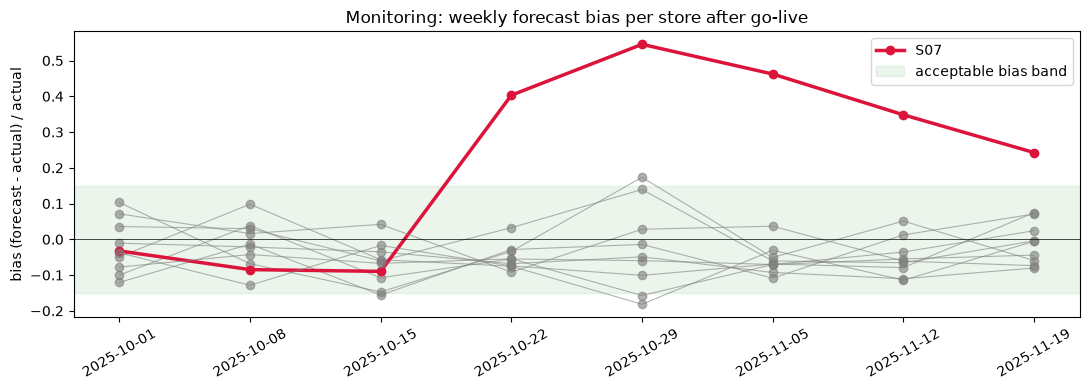

In [22]:
fig, ax = plt.subplots(figsize=(11, 4))
for store, d in monitor.groupby("store_id"):
    ax.plot(d["week_start"].astype(str), d["bias"], marker="o", lw=2.5 if store == "S07" else 0.8,
            color="crimson" if store == "S07" else "grey", alpha=1 if store == "S07" else 0.6,
            label="S07" if store == "S07" else None)
ax.axhspan(-BIAS_ALERT, BIAS_ALERT, color="green", alpha=0.08, label="acceptable bias band")
ax.axhline(0, color="black", lw=0.5)
ax.set_ylabel("bias (forecast - actual) / actual"); ax.set_title("Monitoring: weekly forecast bias per store after go-live")
ax.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**What monitoring tells us:** from the week of 22 October, store S07's forecasts are suddenly far **too high** (bias
+40% to +55%), which means over-stocked shelves and, for FOODS, waste. The alert fires in the **first** week of the change.
Because the model uses lag and rolling features, the bias **shrinks by itself** (to about +24% by the last week) as the
lower sales enter the features, but that slow self-healing would have cost five weeks of excess stock. Typical actions
on an alert: investigate (data problem or real change?), apply a temporary manual adjustment for the store, and retrain.

Four other alerts fired once each (S01, S02, S03 and S10, all between 15% and 18%) and did not repeat the next week:
that is noise. 4 false alarms in 75 normal store-weeks is acceptable; a rule such as "alert only after two weeks in a row"
(exercise 6) would remove all of them but also delay the real S07 alert by a week. Also notice that most stores show a
small **negative** bias (-5% to -10%) in most weeks after go-live: inside the band, but a pattern worth watching (the
model under-forecasts a little in this period).

---
## 17. Automated tests

These would live in `tests/test_forecast.py` and run with `pytest` in CI (see `15_MLOps/07_testing_in_ml/`).

In [23]:
def test_forecast_shape_and_values():
    """Every series gets exactly 14 non-negative, finite forecasts."""
    out = forecast_next_14_days(service_bundle, sales, prices, calendar, TODAY)
    assert len(out) == n_series * CFG.horizon
    assert out["forecast"].between(0, 1e5).all() and out["forecast"].notna().all()
    assert (out["order_qty"] >= 0).all()


def test_point_in_time_features():
    """Features for the forecast days must not depend on future sales."""
    assert_point_in_time(panel, ORIGINS[0], CFG.horizon)


def test_missing_days_are_not_zeros():
    """POS outages must stay NaN in the panel, never become 0."""
    assert panel.loc[panel["is_missing_record"] == 1, "sales"].isna().all()


def test_model_beats_baselines():
    """Quality gate: do not deploy a model that loses to the planner's moving average."""
    assert leaderboard.loc["lgbm", "WAPE"] < leaderboard.loc["ma28", "WAPE"]
    assert leaderboard.loc["lgbm", "WAPE"] < leaderboard.loc["snaive", "WAPE"]


def test_promotion_raises_forecast():
    """Behavioural test: a promotion with a lower price should not lower the forecast."""
    rows = final_feats[final_feats["date"] == TODAY + pd.Timedelta(days=1)].head(50).copy()
    base = final_model.predict(rows[FEATURES].assign(on_promo=0, price_ratio=1.0)).sum()
    promo = final_model.predict(rows[FEATURES].assign(on_promo=1, price_ratio=0.75)).sum()
    assert promo > base, f"{promo:.1f} <= {base:.1f}"


for test in [test_forecast_shape_and_values, test_point_in_time_features, test_missing_days_are_not_zeros,
             test_model_beats_baselines, test_promotion_raises_forecast]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_forecast_shape_and_values


PASSED  point-in-time test at origin 2025-08-05: future sales cannot influence the features
PASSED  test_point_in_time_features
PASSED  test_missing_days_are_not_zeros
PASSED  test_model_beats_baselines
PASSED  test_promotion_raises_forecast


---
## 18. Summary, exercises and resources

| Practice | What we did | Where it is used |
|---|---|---|
| Three source tables | sales (POS), price plan, event calendar | Every retailer; the M5 data has the same structure |
| Complete panel | Missing POS days stay `NaN`, series start at launch | Avoids silently teaching the model fake zeros |
| Demand classes | ADI / CV² (Syntetos-Boylan) | Inventory planning tools (SAP IBP, Blue Yonder, ...) |
| Baselines first | naive, seasonal naive, 28-day moving average | Proves the model adds value |
| Point-in-time features + test | lags >= horizon, poisoned-future test | Prevents the #1 forecasting bug: leakage |
| Global LightGBM, Tweedie loss | one model for 400 series | M5 winners, Nixtla `mlforecast`, skforecast |
| Rolling-origin backtest | 4 origins x 14 days | Hyndman FPP3 "time series cross-validation" |
| WAPE, bias, MASE per group | error analysis by category, class, horizon | Retail forecast-accuracy reporting |
| Recursive vs direct | tested on the same fold | Choosing a multi-step strategy |
| Quantiles + coverage | LightGBM quantile loss, checked | Safety stock, service levels |
| Newsvendor critical ratio | cost-based order quantities | Replenishment / inventory optimisation |
| Bundle + forecast function | saved model, metadata, input checks | Scheduled batch forecasting jobs |
| Monitoring | weekly bias / WAPE per store with alerts | Forecast-value-added and demand-sensing teams |

### Practice exercises
1. Change `horizon` to 7 in the `Config` (weekly ordering). Which lags can you now use, and does WAPE improve?
2. Run `recursive_forecast` on **all** four origins and compare with the direct model. Is the result the same on every fold?
3. Replace the Tweedie objective with `"regression"` (squared error) and compare WAPE and bias for intermittent products.
4. Add a feature "days until the next event" (computed from the calendar, so it is known in advance). Does it help on Labor Day?
5. In section 13, add a starting stock (e.g. 30% of the last 14 days' sales) and order only the difference.
6. Make the monitoring smarter: alert only when the bias is beyond 15% for **two weeks in a row**, and count false alarms.

### Resources (checked)
- M5 Forecasting - Accuracy competition (Kaggle): https://www.kaggle.com/competitions/m5-forecasting-accuracy
- Makridakis, Spiliotis & Assimakopoulos, *The M5 competition: Background, organization, and implementation*, International Journal of Forecasting 38(4), 2022
- Benchmarks and summaries of the winning M5 methods: https://github.com/umitkaanusta/m5-methods
- A top-4% M5 solution using one model per horizon (direct) and a write-up on why: https://github.com/btrotta/kaggle-m5
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.), chapter 5 "The forecaster's toolbox" (accuracy measures incl. MASE, time series cross-validation): https://otexts.com/fpp3/toolbox.html
- Nixtla `mlforecast` (global ML models with lag features, recursive and direct strategies): https://github.com/Nixtla/mlforecast
- skforecast (backtesting, recursive and direct forecasters): https://skforecast.org
- LightGBM parameters (Tweedie and quantile objectives): https://lightgbm.readthedocs.io/en/latest/Parameters.html
- Syntetos, Boylan & Croston (2005), *On the categorization of demand patterns*, JORS: https://doi.org/10.1057/palgrave.jors.2601841

### Related notebooks in this repo
- Lag features, time series CV and multi-step strategies explained: `03_ml_for_forecasting.ipynb`
- Quantile regression, pinball loss and conformal intervals: `09_probabilistic_forecasting.ipynb`
- Hierarchical forecasting and evaluation metrics: `06_advanced_forecasting.ipynb`
- Classical baselines (ETS, ARIMA): `02_classical_methods.ipynb`; companion call-centre project: `12_industry_call_center_staffing_forecast.ipynb`
- Inventory decisions with reinforcement learning: `../11_Reinforcement_Learning/08_industry_inventory_control_with_rl.ipynb`
- Model monitoring tools: `../15_MLOps/06_monitoring/`